In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Folder where all chart images will be saved
os.makedirs("charts", exist_ok=True)

# Same colour for all charts, so the report looks consistent
COLOR = "#028090"

df = pd.read_csv("cleaned_health_data.csv")
print("Rows and columns:", df.shape)
df.head()

Rows and columns: (250, 16)


,Patient_ID,City,Gender,Admission_Type,Insurance_Type,Age,BMI,Fasting_Blood_Sugar,Medications_Count,Distance_To_Hospital_Km,Admission_Date,Hospital_Stay_Days,Age_Group,BMI_Category,Admission_Year,Admission_Month
0,P1066,Mumbai,Male,Referral,Private,56,19.3,127.0,8,9.7,2026-05-30,9,Middle Aged,Normal,2026,5
1,P1231,Chennai,Female,Referral,Government,49,25.8,133.0,2,11.0,2025-12-31,6,Middle Aged,Overweight,2025,12
2,P1106,Bengaluru,Male,Emergency,Uninsured,50,25.4,111.0,3,4.5,2025-07-21,7,Middle Aged,Overweight,2025,7
3,P1167,Bengaluru,Male,Emergency,Government,69,28.5,123.0,3,35.4,2025-05-02,10,Senior,Overweight,2025,5
4,P1040,Delhi,Male,Planned,Uninsured,66,24.5,78.0,5,6.6,2026-07-04,9,Senior,Normal,2026,7


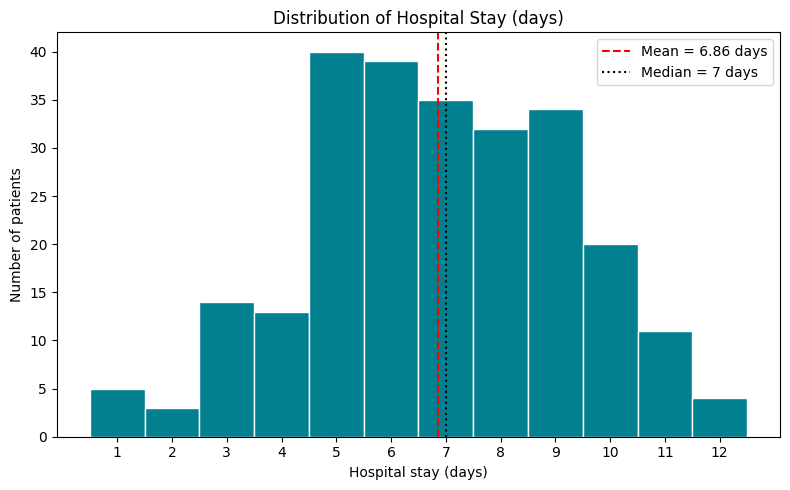

In [2]:
stay = df["Hospital_Stay_Days"]

plt.figure(figsize=(8, 5))
plt.hist(stay, bins=range(1, 14), color=COLOR, edgecolor="white", align="left")
plt.axvline(stay.mean(), color="red", linestyle="--", label=f"Mean = {stay.mean():.2f} days")
plt.axvline(stay.median(), color="black", linestyle=":", label=f"Median = {stay.median():.0f} days")
plt.title("Distribution of Hospital Stay (days)")
plt.xlabel("Hospital stay (days)")
plt.ylabel("Number of patients")
plt.xticks(range(1, 13))
plt.legend()
plt.tight_layout()
plt.savefig("charts/q1_stay_histogram.png", dpi=150)
plt.show()

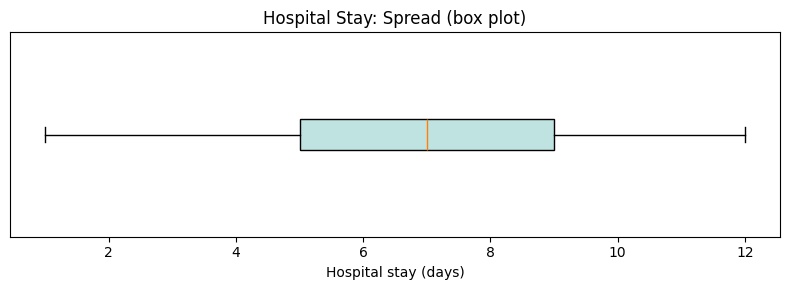

In [3]:
# Box plot: shows median, middle half of patients, shortest and longest stay
plt.figure(figsize=(8, 3))
plt.boxplot(stay, vert=False, patch_artist=True, boxprops=dict(facecolor="#BFE3E0"))
plt.title("Hospital Stay: Spread (box plot)")
plt.xlabel("Hospital stay (days)")
plt.yticks([])
plt.tight_layout()
plt.savefig("charts/q1_stay_boxplot.png", dpi=150)
plt.show()

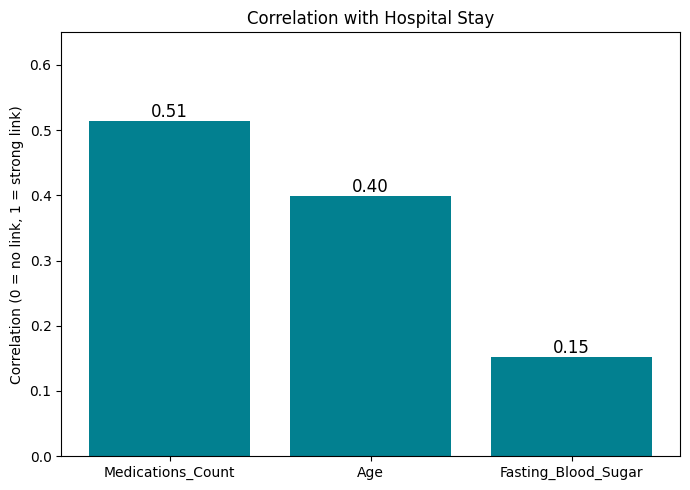

In [4]:
# Chart 2a: correlation of each column with hospital stay
cols = ["Medications_Count", "Age", "Fasting_Blood_Sugar"]
corr = df[cols + ["Hospital_Stay_Days"]].corr()["Hospital_Stay_Days"].drop("Hospital_Stay_Days")
corr = corr.sort_values(ascending=False)

plt.figure(figsize=(7, 5))
bars = plt.bar(corr.index, corr.values, color=COLOR)
plt.bar_label(bars, fmt="%.2f", fontsize=12)
plt.title("Correlation with Hospital Stay")
plt.ylabel("Correlation (0 = no link, 1 = strong link)")
plt.ylim(0, 0.65)
plt.tight_layout()
plt.savefig("charts/q2_correlation.png", dpi=150)
plt.show()

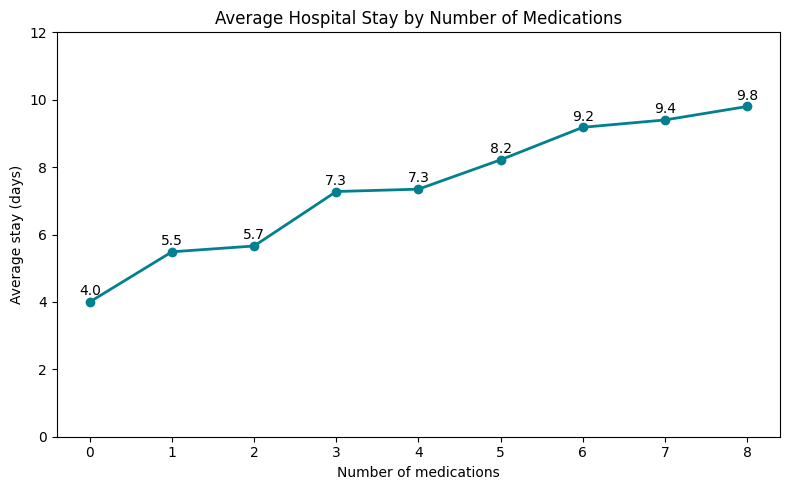

In [5]:
# Chart 2b: average stay for each number of medicines
med = df.groupby("Medications_Count")["Hospital_Stay_Days"].mean()

plt.figure(figsize=(8, 5))
plt.plot(med.index, med.values, marker="o", color=COLOR, linewidth=2)
for x, y in zip(med.index, med.values):
    plt.text(x, y + 0.2, f"{y:.1f}", ha="center")
plt.title("Average Hospital Stay by Number of Medications")
plt.xlabel("Number of medications")
plt.ylabel("Average stay (days)")
plt.ylim(0, 12)
plt.tight_layout()
plt.savefig("charts/q2_medications_vs_stay.png", dpi=150)
plt.show()

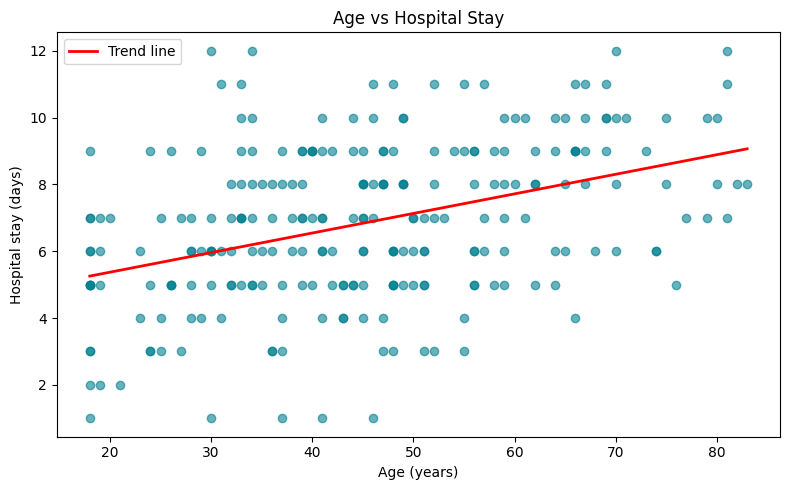

In [6]:
# Chart 2c: age against hospital stay (each dot is one patient)
plt.figure(figsize=(8, 5))
plt.scatter(df["Age"], df["Hospital_Stay_Days"], color=COLOR, alpha=0.6)

# Straight trend line using NumPy
slope, intercept = np.polyfit(df["Age"], df["Hospital_Stay_Days"], 1)
x = np.array([df["Age"].min(), df["Age"].max()])
plt.plot(x, slope * x + intercept, color="red", linewidth=2, label="Trend line")

plt.title("Age vs Hospital Stay")
plt.xlabel("Age (years)")
plt.ylabel("Hospital stay (days)")
plt.legend()
plt.tight_layout()
plt.savefig("charts/q2_age_vs_stay.png", dpi=150)
plt.show()

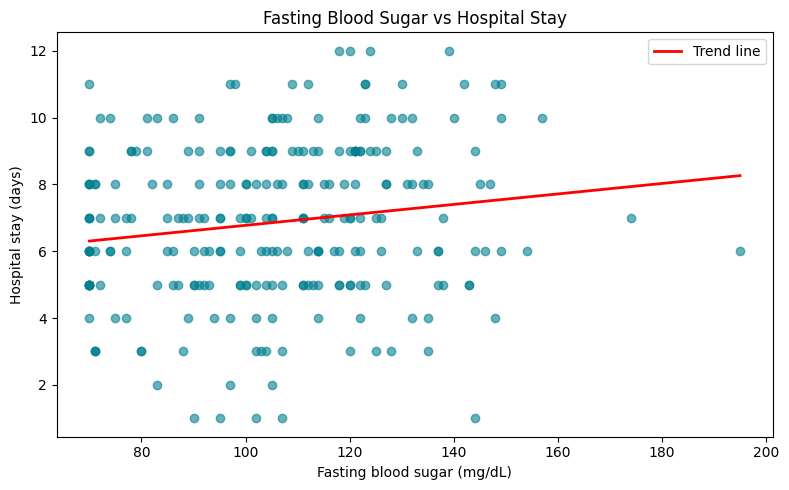

In [7]:
# Chart 2d: fasting blood sugar against hospital stay
plt.figure(figsize=(8, 5))
plt.scatter(df["Fasting_Blood_Sugar"], df["Hospital_Stay_Days"], color=COLOR, alpha=0.6)
slope, intercept = np.polyfit(df["Fasting_Blood_Sugar"], df["Hospital_Stay_Days"], 1)
x = np.array([df["Fasting_Blood_Sugar"].min(), df["Fasting_Blood_Sugar"].max()])
plt.plot(x, slope * x + intercept, color="red", linewidth=2, label="Trend line")
plt.title("Fasting Blood Sugar vs Hospital Stay")
plt.xlabel("Fasting blood sugar (mg/dL)")
plt.ylabel("Hospital stay (days)")
plt.legend()
plt.tight_layout()
plt.savefig("charts/q2_sugar_vs_stay.png", dpi=150)
plt.show()

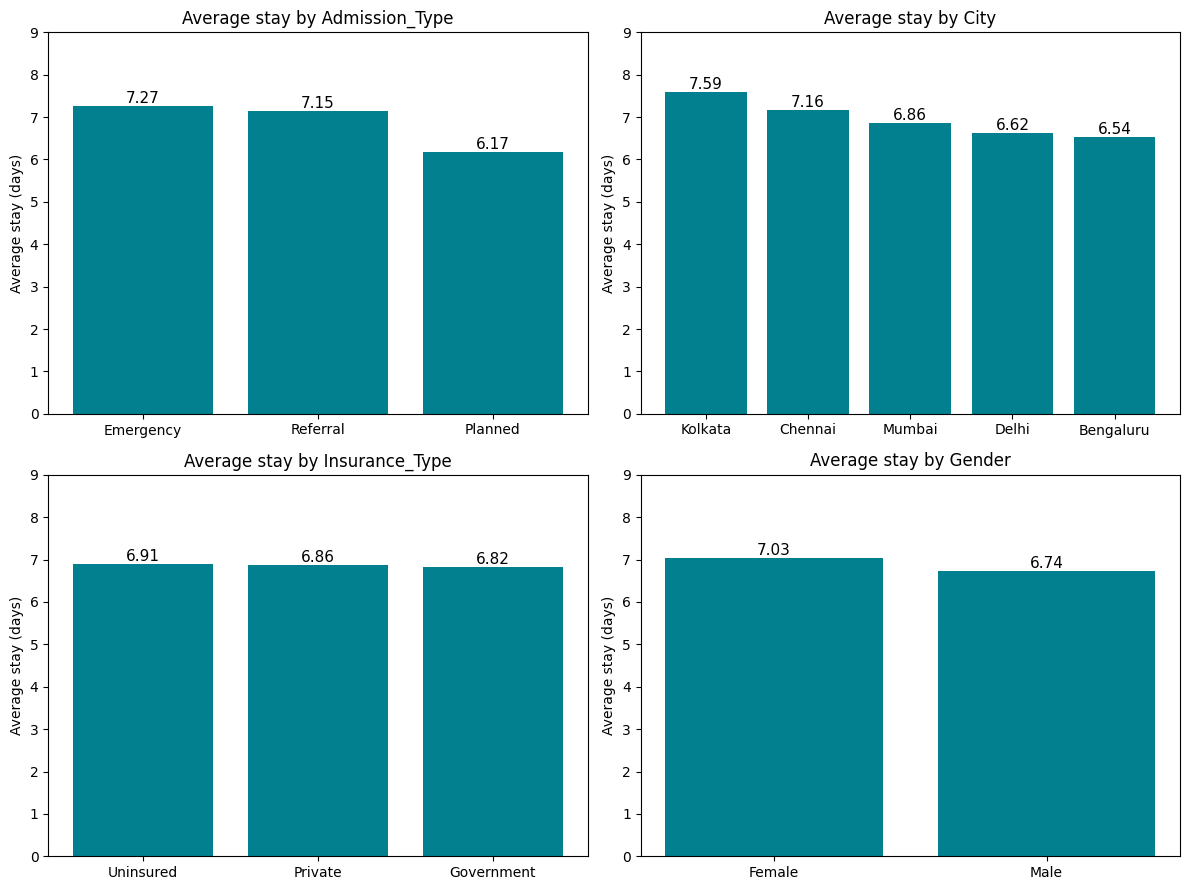

In [8]:
# Four bar charts in one picture (2 rows x 2 columns)
groups = ["Admission_Type", "City", "Insurance_Type", "Gender"]

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.flatten()

for ax, col in zip(axes, groups):
    avg = df.groupby(col)["Hospital_Stay_Days"].mean().sort_values(ascending=False)
    bars = ax.bar(avg.index, avg.values, color=COLOR)
    ax.bar_label(bars, fmt="%.2f", fontsize=11)
    ax.set_title("Average stay by " + col)
    ax.set_ylabel("Average stay (days)")
    ax.set_ylim(0, 9)

plt.tight_layout()
plt.savefig("charts/q3_stay_by_groups.png", dpi=150)
plt.show()

Long_Stay
Normal       215
Long Stay     35
Name: count, dtype: int64


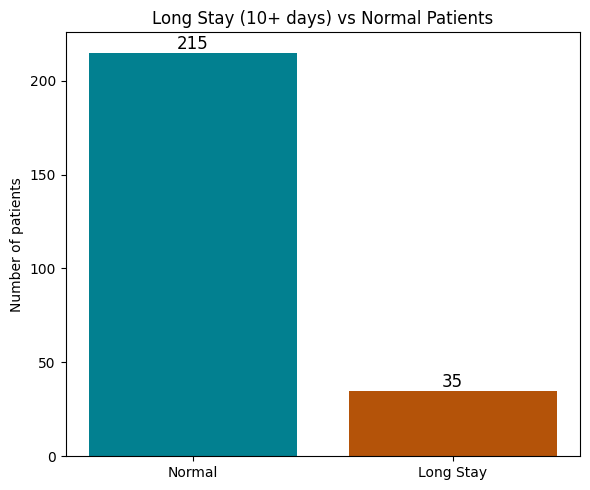

In [9]:
# Create the Long_Stay column
df["Long_Stay"] = np.where(df["Hospital_Stay_Days"] >= 10, "Long Stay", "Normal")
print(df["Long_Stay"].value_counts())

counts = df["Long_Stay"].value_counts()
plt.figure(figsize=(6, 5))
bars = plt.bar(counts.index, counts.values, color=[COLOR, "#B45309"])
plt.bar_label(bars, fontsize=12)
plt.title("Long Stay (10+ days) vs Normal Patients")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.savefig("charts/q4_long_stay_count.png", dpi=150)
plt.show()

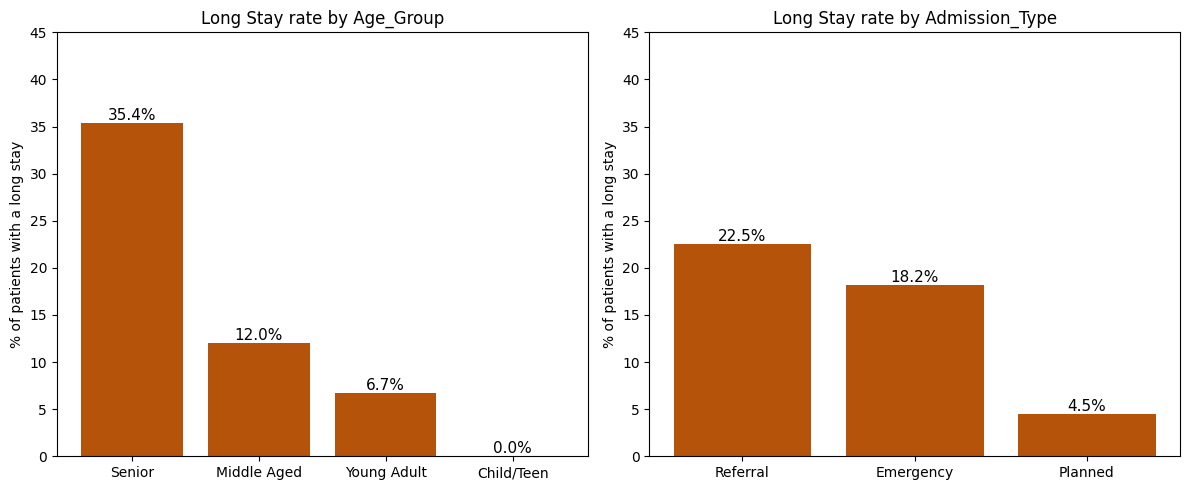

In [10]:
# What do Long Stay patients have in common?
# Percentage of Long Stay patients in each age group and admission type
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ["Age_Group", "Admission_Type"]):
    pct = (df["Long_Stay"].eq("Long Stay").groupby(df[col]).mean() * 100).sort_values(ascending=False)
    bars = ax.bar(pct.index, pct.values, color="#B45309")
    ax.bar_label(bars, fmt="%.1f%%", fontsize=11)
    ax.set_title("Long Stay rate by " + col)
    ax.set_ylabel("% of patients with a long stay")
    ax.set_ylim(0, 45)

plt.tight_layout()
plt.savefig("charts/q4_long_stay_rate.png", dpi=150)
plt.show()

            Age  Medications_Count
Long_Stay                         
Long Stay  57.3                4.4
Normal     43.4                2.9


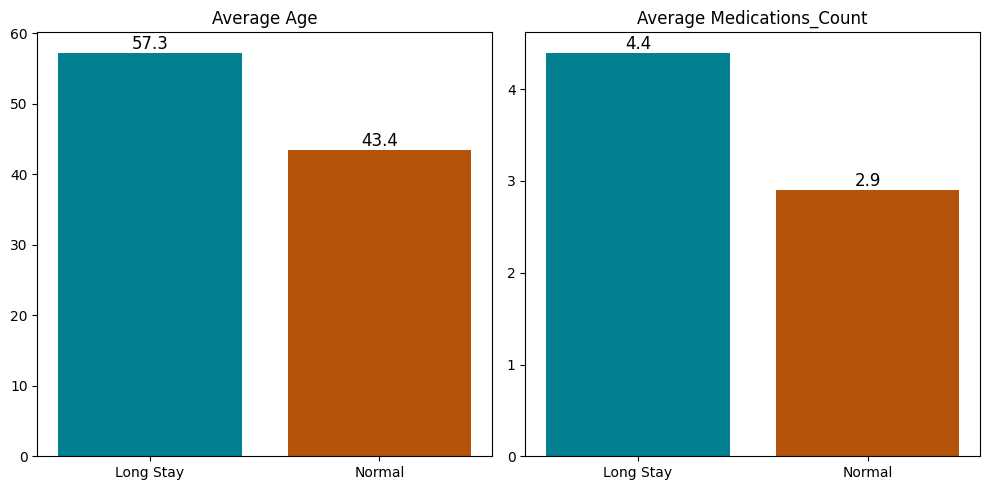

In [11]:
# Long Stay patients compared with the others: average age and medications
compare = df.groupby("Long_Stay")[["Age", "Medications_Count"]].mean().round(1)
print(compare)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, col in zip(axes, ["Age", "Medications_Count"]):
    bars = ax.bar(compare.index, compare[col], color=[COLOR, "#B45309"])
    ax.bar_label(bars, fontsize=12)
    ax.set_title("Average " + col)

plt.tight_layout()
plt.savefig("charts/q4_long_stay_profile.png", dpi=150)
plt.show()

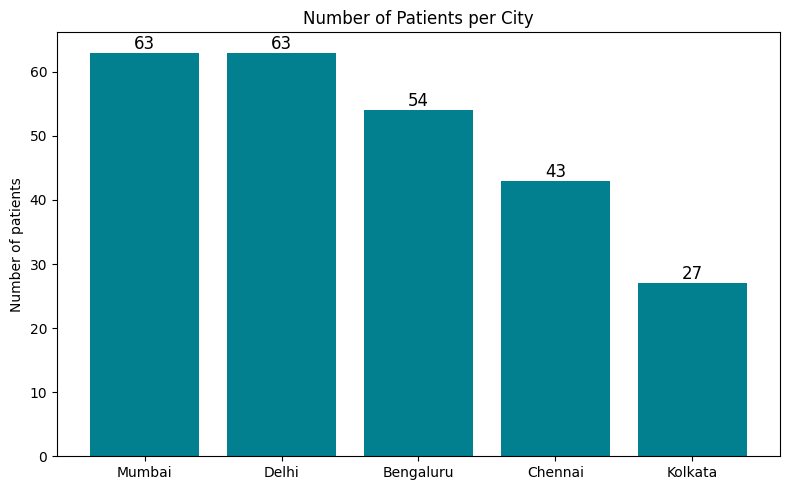

In [12]:
city = df["City"].value_counts()

plt.figure(figsize=(8, 5))
bars = plt.bar(city.index, city.values, color=COLOR)
plt.bar_label(bars, fontsize=12)
plt.title("Number of Patients per City")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.savefig("charts/extra_patients_per_city.png", dpi=150)
plt.show()